## Assessment 1 - Exercise 1: Multi-Layer Perceptron (MLP) on CIFAR-10

### Importing packages and testing that they work
Import PyTorch, Torchvision, Matplotlib, and NumPy, check the installed versions and GPU availability.

Select the GPU (cuda) if available otherwise fall back to the CPU for all operations.

In [1]:
import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

PyTorch version: 2.15.0+cu132
Torchvision version: 0.29.2+cu132
GPU available: True


In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


---
### Loading and Exploring the CIFAR-10 Dataset
Download and load the CIFAR-10 training (50,000 images) and test (10,000 images) datasets, transforming images into PyTorch tensors scaled to [0.0, 1.0].

In [3]:
transform = transforms.ToTensor()

train_dataset = torchvision.datasets.CIFAR10(
    root="../data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="../data",
    train=False,
    download=True,
    transform=transform
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))

Training images: 50000
Testing images: 10000


### Inspecting a Single Sample Tensor
Check the tensor shape (`3 × 32 × 32`), label index, data type, and pixel value range.

In [4]:
image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Label:", label)
print("Image data type:", image.dtype)
print("Minimum pixel value:", image.min().item())
print("Maximum pixel value:", image.max().item())

Image shape: torch.Size([3, 32, 32])
Label: 6
Image data type: torch.float32
Minimum pixel value: 0.0
Maximum pixel value: 1.0


### Visualising Sample Images
Display a single sample image and a 2 × 5 grid of the first 10 training images with their corresponding CIFAR-10 class names.

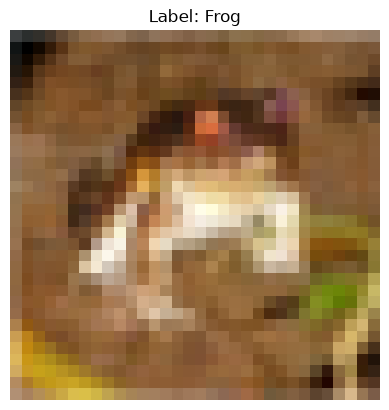

In [5]:
classes = (
    "Airplane", "Automobile", "Bird", "Cat", "Deer",
    "Dog", "Frog", "Horse", "Ship", "Truck"
)

image, label = train_dataset[0]

plt.imshow(image.permute(1, 2, 0))
plt.title(f"Label: {classes[label]}")
plt.axis("off")
plt.show()

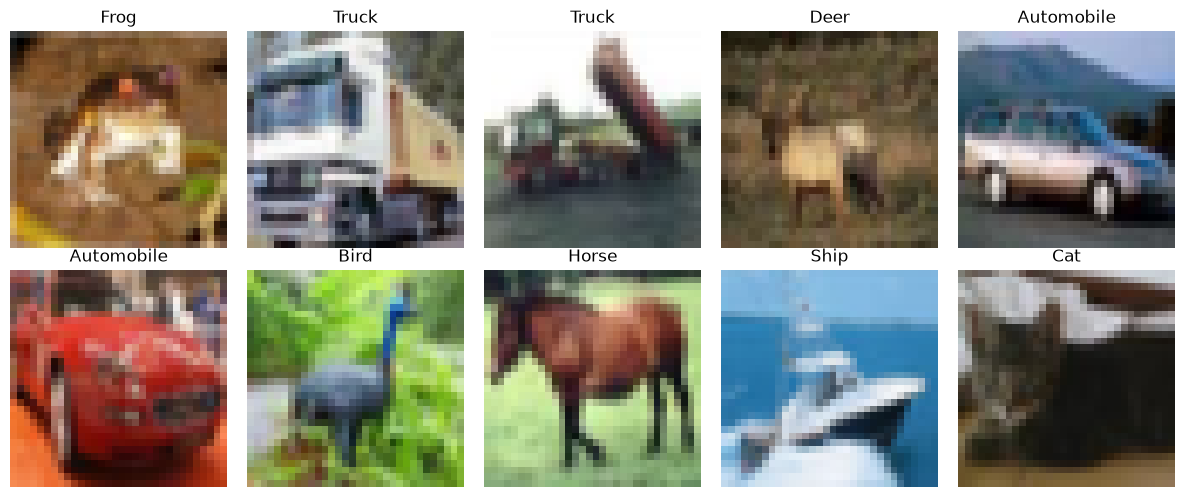

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]

    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(classes[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

---
### Train, Validation, and Test DataLoaders
Split the 50,000 training images into 40,000 training and 10,000 validation using a fixed manual seed for reproducibility. Then create DataLoader objects of batch size of 64.

In [7]:
from torch.utils.data import random_split, DataLoader

total_size = len(train_dataset)
train_size = int(0.8 * total_size)  # 40,000 images (80%)
val_size = total_size - train_size  # 10,000 images (20%)

# Using a manual seed so the split is reproducible every time
generator = torch.Generator().manual_seed(42)
train_subset, val_subset = random_split(
    train_dataset,
    [train_size, val_size],
    generator=generator
)

print(f"Training samples: {len(train_subset)}")
print(f"Validation samples: {len(val_subset)}")

# Create DataLoaders for your MLP training loop
train_loader = DataLoader(train_subset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_subset, batch_size=64, shuffle=False)

Training samples: 40000
Validation samples: 10000


In [8]:
# Create DataLoader for the test dataset
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)
print(f"Test samples: {len(test_dataset)}")

Test samples: 10000


### Verifying Batch Dimensions and Flattened Input Shape
Inspect a single mini-batch from train_loader to confirm the image tensor shape [64, 3, 32, 32] and the flattened vector dimension 3072 (3 × 32 × 32) required by the MLP.

In [9]:
images, labels = next(iter(train_loader))

# Inspect raw batch dimensions
print("Batch images shape:", images.shape)
print("Batch labels shape:", labels.shape)
print("Images dtype:", images.dtype)
print("Labels dtype:", labels.dtype)

# Preview the first 5 labels in the batch
print("First 5 label indices:", labels[:5].tolist())
print("First 5 class names:", [classes[idx] for idx in labels[:5]])

# Confirm flattened dimensions for th MLP
flattened_images = images.view(images.size(0), -1)
print("Flattened images shape for MLP:", flattened_images.shape)

Batch images shape: torch.Size([64, 3, 32, 32])
Batch labels shape: torch.Size([64])
Images dtype: torch.float32
Labels dtype: torch.int64
First 5 label indices: [7, 5, 7, 5, 1]
First 5 class names: ['Horse', 'Dog', 'Horse', 'Dog', 'Automobile']
Flattened images shape for MLP: torch.Size([64, 3072])


---
### Defining the 3-Layer Multi Layer Perceptron (MLP)
Define the MLP architecture with three trainable layers and ReLU activation functions between the layers.
* Layer 1 : 3072 → 512
* ReLU 1
* Layer 2 : 512 → 256
* ReLU 2 
* Layer 3 : 256 → 10

In [10]:
import torch
import torch.nn as nn

class MLP(nn.Module):

    def __init__(self):
        super().__init__()

        self.flatten = nn.Flatten()

        self.layer1 = nn.Linear(3072, 512)
        self.relu1 = nn.ReLU()

        self.layer2 = nn.Linear(512, 256)
        self.relu2 = nn.ReLU()

        self.layer3 = nn.Linear(256, 10)

    def forward(self, x):

        x = self.flatten(x)

        x = self.layer1(x)
        x = self.relu1(x)

        x = self.layer2(x)
        x = self.relu2(x)

        x = self.layer3(x)

        return x

### Model Summary
Instantiate the model, inspect the total number of trainable parameters, and verify a single forward pass on one training batch before training.

In [11]:
model = MLP().to(device)

print(model)

MLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (layer1): Linear(in_features=3072, out_features=512, bias=True)
  (relu1): ReLU()
  (layer2): Linear(in_features=512, out_features=256, bias=True)
  (relu2): ReLU()
  (layer3): Linear(in_features=256, out_features=10, bias=True)
)


In [12]:
total_params = sum(
    p.numel() for p in model.parameters()
)

print("Total parameters:", total_params)

Total parameters: 1707274


In [13]:
images, labels = next(iter(train_loader))

In [14]:
print("Input shape:", images.shape)
print("Labels shape:", labels.shape)

Input shape: torch.Size([64, 3, 32, 32])
Labels shape: torch.Size([64])


In [15]:
outputs = model(images.to(device))

print("Output shape:", outputs.shape)

Output shape: torch.Size([64, 10])


In [16]:
class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

# Get the first image's output scores
first_output = outputs[0]

print("Actual label:", class_names[labels[0].item()])
print("Output scores:", first_output)

# Get the predicted class
predicted_class = torch.argmax(first_output).item()

print("Predicted class:", class_names[predicted_class])

Actual label: frog
Output scores: tensor([-0.0425, -0.0989,  0.0083,  0.0284, -0.0097, -0.0270, -0.0622, -0.0943,
        -0.0669, -0.0411], device='cuda:0', grad_fn=<SelectBackward0>)
Predicted class: cat


---
### Loss Function and Optimizer
Initialize a fresh MLP instance with CrossEntropyLoss and the Adam optimizer (lr=0.001).

In [17]:
model = MLP().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

---
### Training Model
Training the model with 15 epochs.

In [18]:
train_losses = []
val_losses = []

num_epochs = 15

In [19]:
train_accs = []
val_accs = []

for epoch in range(num_epochs):

    # Training
    model.train()

    running_train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_train_loss += loss.item() * labels.size(0)
        _, predicted = torch.max(outputs, 1)
        train_total += labels.size(0)
        train_correct += (predicted == labels).sum().item()

    epoch_train_loss = running_train_loss / train_total
    epoch_train_acc = 100 * train_correct / train_total

    train_losses.append(epoch_train_loss)
    train_accs.append(epoch_train_acc)

    # Validation
    model.eval()

    running_val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_val_loss += loss.item() * labels.size(0)
            _, predicted = torch.max(outputs, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    epoch_val_loss = running_val_loss / val_total
    epoch_val_acc = 100 * val_correct / val_total

    val_losses.append(epoch_val_loss)
    val_accs.append(epoch_val_acc)

    # Display results
    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Training Loss: {epoch_train_loss:.4f} (Acc: {epoch_train_acc:.2f}%) | "
        f"Validation Loss: {epoch_val_loss:.4f} (Acc: {epoch_val_acc:.2f}%)"
    )

Epoch [1/15] Training Loss: 1.8676 (Acc: 31.91%) | Validation Loss: 1.7247 (Acc: 37.81%)
Epoch [2/15] Training Loss: 1.6901 (Acc: 39.30%) | Validation Loss: 1.6365 (Acc: 40.96%)
Epoch [3/15] Training Loss: 1.6022 (Acc: 42.68%) | Validation Loss: 1.5916 (Acc: 42.67%)
Epoch [4/15] Training Loss: 1.5537 (Acc: 44.42%) | Validation Loss: 1.5788 (Acc: 43.40%)
Epoch [5/15] Training Loss: 1.5079 (Acc: 46.20%) | Validation Loss: 1.5181 (Acc: 45.61%)
Epoch [6/15] Training Loss: 1.4780 (Acc: 47.14%) | Validation Loss: 1.4887 (Acc: 46.72%)
Epoch [7/15] Training Loss: 1.4473 (Acc: 48.44%) | Validation Loss: 1.5166 (Acc: 45.33%)
Epoch [8/15] Training Loss: 1.4281 (Acc: 48.90%) | Validation Loss: 1.4693 (Acc: 47.71%)
Epoch [9/15] Training Loss: 1.4037 (Acc: 49.77%) | Validation Loss: 1.4480 (Acc: 48.69%)
Epoch [10/15] Training Loss: 1.3773 (Acc: 50.72%) | Validation Loss: 1.4682 (Acc: 47.32%)
Epoch [11/15] Training Loss: 1.3559 (Acc: 51.44%) | Validation Loss: 1.4283 (Acc: 49.43%)
Epoch [12/15] Train

---
### Model Evaluation and Performance Graphs
Training loss vs validation loss graph and training accuracy vs validation accuracy graph across the 15 epochs.

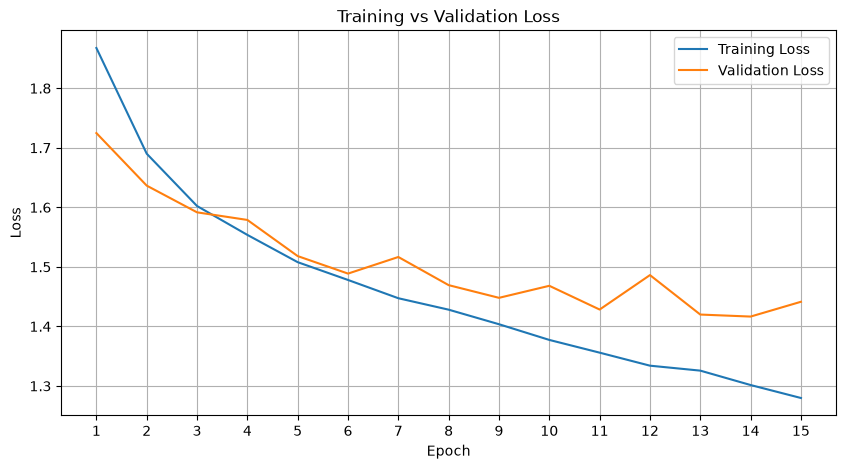

In [20]:
epochs = range(1, num_epochs + 1)

plt.figure(figsize=(10, 5))

plt.plot(epochs, train_losses, label="Training Loss")
plt.plot(epochs, val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")

plt.xticks(epochs)
plt.legend()
plt.grid(True)

plt.show()

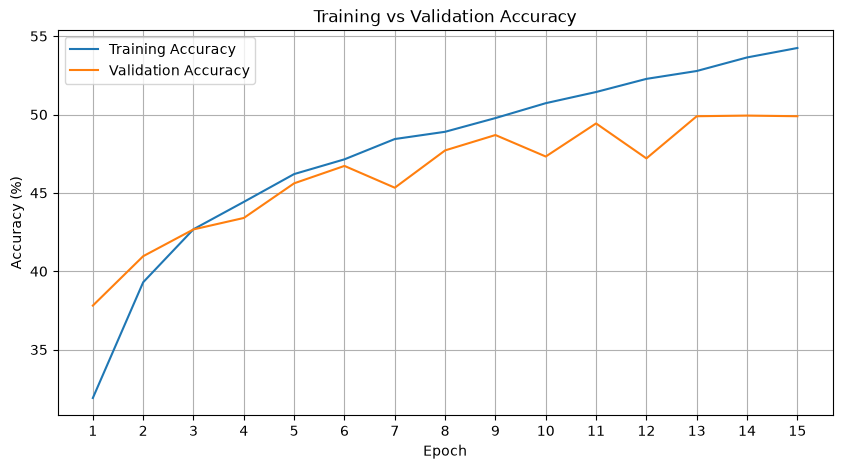

In [21]:
plt.figure(figsize=(10, 5))

plt.plot(epochs, train_accs, label="Training Accuracy")
plt.plot(epochs, val_accs, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training vs Validation Accuracy")

plt.xticks(epochs)
plt.legend()
plt.grid(True)

plt.show()

### Training Accuracy
Evaluate the trained model's final accuracy on the training dataset.

In [22]:
model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print(f"Training Accuracy: {accuracy:.2f}%")

Training Accuracy: 55.99%


### Validation Accuracy
Evaluate the trained model's final accuracy on the validation dataset.

In [23]:
model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

val_accuracy = 100 * correct / total

print(f"Validation Accuracy: {val_accuracy:.2f}%")

Validation Accuracy: 49.89%


### Test Accuracy
Evaluate the trained model's final accuracy on the held-out `10,000`-image test dataset.

In [24]:
# Evaluate on the unseen Test Dataset (10,000 images)
model.eval()

correct = 0
total = 0
all_preds = []
all_targets = []

with torch.no_grad():

    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        all_preds.extend(predicted.cpu().numpy())
        all_targets.extend(labels.cpu().numpy())

test_accuracy = 100 * correct / total

print(f"Test Accuracy: {test_accuracy:.2f}%")

Test Accuracy: 49.75%


### Test Set Confusion Matrix
The confusion matrix on the CIFAR-10 test set to visualise per-class predictions and misclassifications.

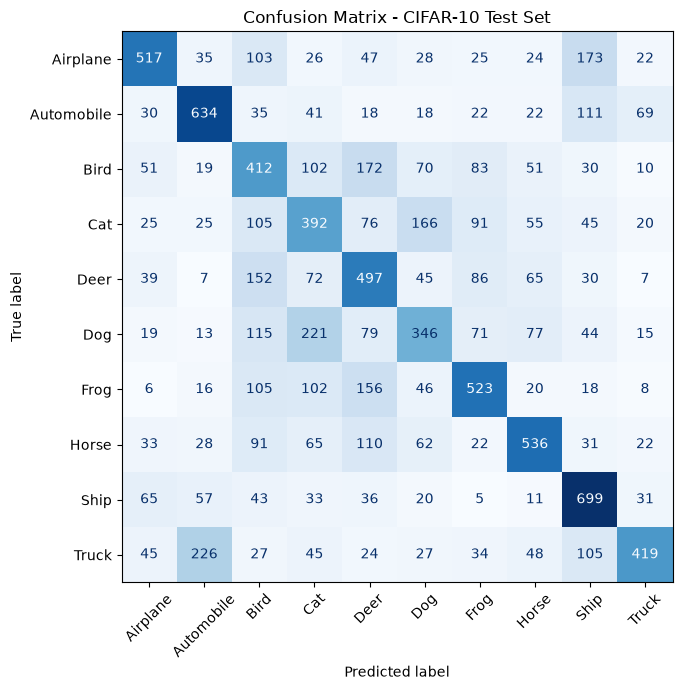

In [25]:
# Confusion Matrix on the Test Dataset
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(all_targets, all_preds)
fig, ax = plt.subplots(figsize=(9, 7))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
plt.title("Confusion Matrix - CIFAR-10 Test Set")
plt.tight_layout()
plt.show()

---
### Saving and Loading the Trained Model
Save the learned model weights to mlp_cifar10.pth and reload them into a new MLP instance for inference.

In [26]:
torch.save(model.state_dict(), "mlp_cifar10.pth")

print("Model saved successfully!")

Model saved successfully!


In [27]:
loaded_model = MLP().to(device)

In [28]:
loaded_model.load_state_dict(
    torch.load("mlp_cifar10.pth", map_location=device, weights_only=True)
)

<All keys matched successfully>

In [29]:
loaded_model.eval()

print("Model loaded successfully!")

Model loaded successfully!


---
### Single-Image & Grid Inference on the Test Dataset
Test the loaded model on images from test_dataset (indexed from 0 to 9999). Change test_index below to inspect any specific test image or set test_index = None to pick a random test image.

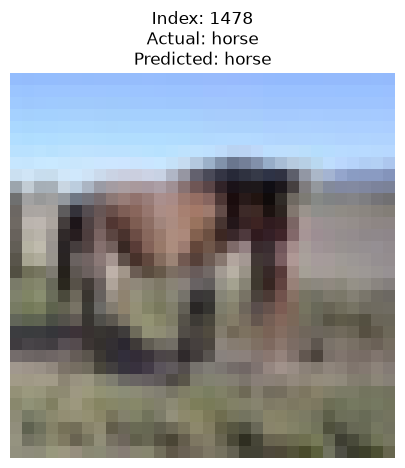

In [43]:
# Set test_index to any integer from 0 to 9999 or None for a random test image
test_index = None

if test_index is None:
    test_index = np.random.randint(0, len(test_dataset))

image, actual_label = test_dataset[test_index]
image_batch = image.unsqueeze(0).to(device)

loaded_model.eval()
with torch.no_grad():
    output = loaded_model(image_batch)
    predicted_label = torch.argmax(output, dim=1).item()

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

plt.figure(figsize=(5, 5))
plt.imshow(image.permute(1, 2, 0))
plt.title(
    f"Index: {test_index}\n"
    f"Actual: {class_names[actual_label]}\n"
    f"Predicted: {class_names[predicted_label]}"
)
plt.axis("off")
plt.show()


### Grid of 10 Test Set Predictions
Visualise predictions across 10 randomly selected images from test_dataset.

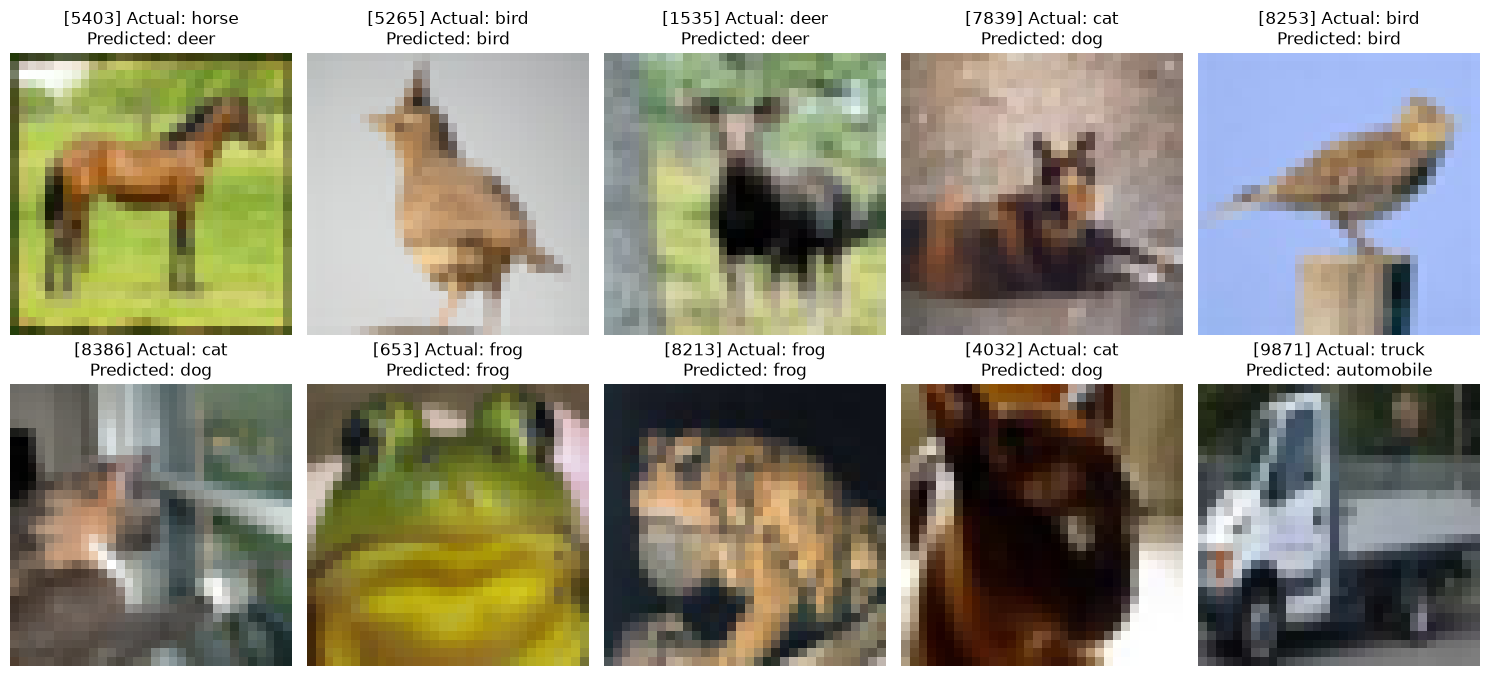

In [44]:
fig, axes = plt.subplots(2, 5, figsize=(15, 7))

loaded_model.eval()
random_indices = np.random.choice(len(test_dataset), size=10, replace=False)

for idx, ax in zip(random_indices, axes.flat):

    image, actual_label = test_dataset[idx]

    with torch.no_grad():

        output = loaded_model(image.unsqueeze(0).to(device))

        predicted_label = torch.argmax(output, dim=1).item()

    ax.imshow(image.permute(1, 2, 0))

    ax.set_title(
        f"[{idx}] Actual: {class_names[actual_label]}\n"
        f"Predicted: {class_names[predicted_label]}"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()
